In [155]:
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import random as rnd
from scipy import stats
from scipy.optimize import brentq

Hs = 7 #m wave height
h = 25 #m depth 
St = 0.15 #steepness k*a
pi = np.pi
g = 9.81

Lambda = pi * Hs/St
kp = 2*pi/Lambda
Tp = np.sqrt(Lambda / np.tanh(2*pi*h/Lambda) * 2 *pi /g)

print(f"Wavelength: {Lambda:.2f} m")
print(f"Tp: {Tp:.2f} s")
print(f"k: {kp:.2f} ")

Wavelength: 146.61 m
Tp: 10.90 s
k: 0.04 


Peak period: 10.90 s
Peak frequency: 0.0917 Hz


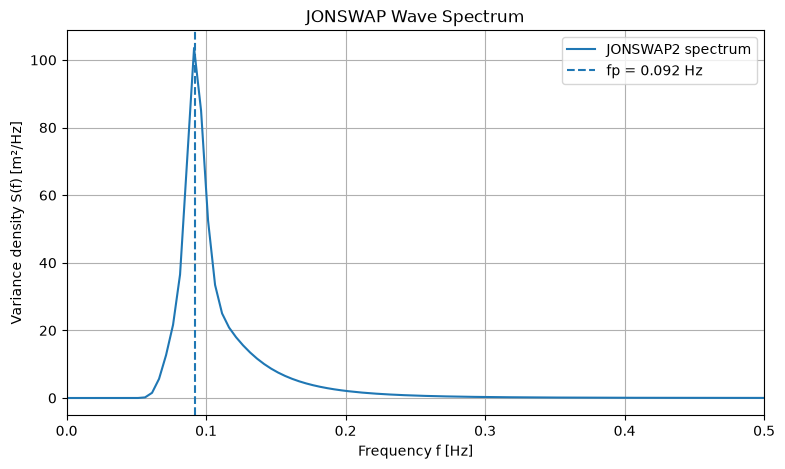

In [156]:

import matplotlib.pyplot as plt

# JONSWAP parameters
gamma = 3.3
fp = 1 / Tp

# Frequency range (avoid f = 0)
f = np.linspace(0.001, 1.0, 200)
df = f[1]-f[0]

# Spectral width
sigma = np.where(f <= fp, 0.07, 0.09)

# Peak enhancement exponent
r = np.exp(-(f - fp)**2 / (2 * sigma**2 * fp**2))

# Pierson-Moskowitz

Epm = 5/16*Hs**2*fp**4*f**-5*np.exp(-5/4*(fp/f)**4)
Alpha = 1-0.287*np.log(gamma)

# JONSWAP spectral shape (initially alpha = 1)
#S = (g**2 / ((2*np.pi)**4 * f**5)) * \
    #np.exp(-1.25 * (fp/f)**4) * gamma**r
S2 = Alpha*Epm*gamma**r


print(f"Peak period: {Tp:.2f} s")
print(f"Peak frequency: {fp:.4f} Hz")


# Plot spectrum
plt.figure(figsize=(9, 5))
#plt.plot(f, S, label="JONSWAP spectrum")
plt.plot(f,S2, label="JONSWAP2 spectrum")
plt.axvline(fp, linestyle="--", label=f"fp = {fp:.3f} Hz")

plt.xlabel("Frequency f [Hz]")
plt.ylabel("Variance density S(f) [m²/Hz]")
plt.title("JONSWAP Wave Spectrum")
plt.legend()
plt.grid(True)
plt.xlim(0, 0.5)
plt.show()


In [157]:
m0_test = Hs**2/16
m0 = np.trapezoid(S2, f)
Hs_0 = 4 * np.sqrt(m0)

m_minus1 = np.trapezoid(S2/f, f)
m1 = np.trapezoid(f*S2, f)
m2 = np.trapezoid(f**2*S2,f)
m4 = np.trapezoid(f**4*S2,f)

# epsilon below 0.9 is often addmissable for narrow banded. 
epsilon = np.sqrt(1-m2**2/(m0*m4)) 

print(f"m0_test: {m0_test}")
print(f"m0: {m0}")
print(f"Hs_0: {Hs_0} \n")

print(f"m-1 = {m_minus1:.4f} m²s")
print(f"m1  = {m1:.4f} m²/s")
print(f"m2  = {m2:.4f} m²/s²")
print(f"m4  = {m4:.4f} m²/s² \n" )

print(f'epsilon= {epsilon} \n')


Tm = np.sqrt(m0 / m2)
Tm_10 = m_minus1 / m0
Tm01 = m0 / m1

print(f"Tm  = {Tm:.2f} s")
print(f"Tm-10 = {Tm_10:.2f} s")
print(f"Tm01  = {Tm01:.2f} s")

m0_test: 3.0625
m0: 3.070599773331331
Hs_0: 7.00925077118099 

m-1 = 30.2415 m²s
m1  = 0.3373 m²/s
m2  = 0.0424 m²/s²
m4  = 0.0016 m²/s² 

epsilon= 0.8020872500877838 

Tm  = 8.51 s
Tm-10 = 9.85 s
Tm01  = 9.10 s


In [158]:
from scipy.optimize import newton

omega = 2*pi/Tp
k = newton(
    func=lambda k: g*k*np.tanh(k*h) - omega**2,
    x0=omega**2/g,
    fprime=lambda k: (
        g*np.tanh(k*h)
        + g*k*h/np.cosh(k*h)**2
    )
)

L = 2*np.pi/k
s_new = (Hs/L)*pi

print(f'k = {k}')
print(f's_new = {s_new}')

k = 0.04285714285714285
s_new = 0.14999999999999997


0.4877625506496716


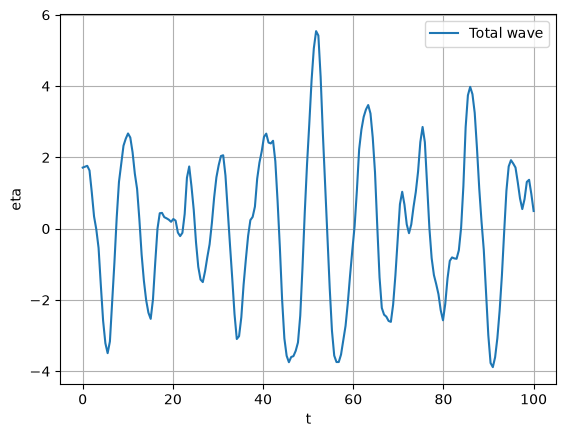

In [159]:
# rnd.seed(5) # om random phase shift gelijk te houden per simulatie

# alpha als willekeurige phase shift tussen 0 en 2pi
N = 200
teta = [rnd.randrange(0, 200) * np.pi / 100 for _ in range(N)]

def calculate_k(f, h):
    omega = 2 * np.pi * f

    def dispersion(k):
        return g * k * np.tanh(k * h) - omega**2

    return brentq(dispersion, 1e-8, 100)

t = np.linspace(0, 100, 200) # tijdstappen
eta = np.zeros(len(t)) # golfhoogte
k = [calculate_k(fi, h) for fi in f] # wavenumbers per golf
derivat = np.zeros(len(t)) # afgeleide van eta over tijd
lambd = np.array(2 * np.pi) / k
# hor_vel = np.


for i in range(len(eta)): # loop over elke tijdstap om hier de wave height te bepalen
    for j in range(len(f)): # loop over elke frequentie om de samengestelde golf te bepalen
        a = np.sqrt(2 * S2[j] * df) # amplitude van de golf
        eta[i] += a * np.cos(2*np.pi*f[j]*t[i] + teta[j])
        derivat[i] += -a*k[j]*np.sin(2*np.pi*f[j]*t[i] + teta[j])


plt.plot(t, eta, label="Total wave")
plt.xlabel("t")
plt.ylabel("eta")
plt.legend()
plt.grid()

max_steep = np.max(np.abs(derivat))
print(max_steep)

In [160]:
from scipy.signal import hilbert

z = hilbert(eta)
At = abs(z)
Tet = np.angle(z)

kh = kp*h

G = (np.cosh(kh)*(2+np.cosh(2*kh))/
    (4*np.sinh(kh)**3))

print(f'G = {G}')

eta_super = G * kp * At **2 * np.cos(2*Tet)

eta_2n_order = eta + eta_super

G = 1.2047284318693607


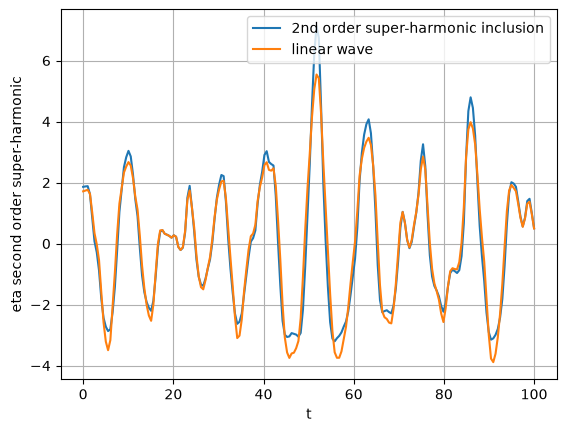

In [161]:
plt.plot(t, eta_2n_order, label="2nd order super-harmonic inclusion")
plt.plot(t,eta, label = 'linear wave')
plt.xlabel("t")
plt.ylabel("eta second order super-harmonic")
plt.legend()
plt.grid()

In [ ]:
# parameter calculations

kh = kp * h
ka = kp * Hs/2
Ur = Hs*Lambda**2/h**3
kc = 0
Re = 0

print("\n--- Wave Parameters ---")
print(f"Relative water depth (kh) : {kh:.4f} [-]")
print(f"Wave steepness (ka)       : {ka:.4f} [-]")
print(f"Ursell number (Ur)        : {Ur:.4f} [-]")
print(f"Wave number (kp)          : {kp:.5f} [1/m]")
print(f"Wave length (Lambda)      : {Lambda:.2f} [m]")
print(f"Peak period (Tp)          : {Tp:.2f} [s]")
print(f"KC number                 : {kc:.4f} [-]")
print(f"Reynolds number (Re)      : {Re:.2e} [-]")
print("-----------------------")


--- Wave Parameters ---
Relative water depth (kh) : 1.0714 [-]
Wave steepness (ka)       : 0.1500 [-]
Ursell number (Ur)        : 9.6292 [-]
Wave number (kp)          : 0.04286 [1/m]
Wave length (Lambda)      : 146.61 [m]
Peak period (Tp)          : 10.90 [s]
KC number                 : 0.0000 [-]
Reynolds number (Re)      : 0.00e+00 [-]
-----------------------
